In [1]:
# Geass imports
import geass, molecular_structure_clustering
import time
import re
import ipycytoscape
import pickle
import networkx as nx
from collections import Counter
from rdkit.Chem.Draw import rdMolDraw2D
from urllib import parse
from rdkit import Chem
from rdkit.Chem import rdChemReactions as Reactions
from scipy.spatial.distance import pdist,squareform

allChars = '0123456789abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ'
print('Networkx version :', nx.__version__)

Networkx version : 2.2


In [2]:
# Metabolic Disassembler imports
import glob
import sys
import rdkit
import pandas.io.formats.html
import os
import copy
import json
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import metadisassembler5 as medi5

from rdkit import Chem
from rdkit.Chem.PandasTools import LoadSDF
from rdkit.Chem.Draw import IPythonConsole
from IPython.display import Image, display_png, clear_output

# 1. Run Geass

**Note:** This will be the same as in the notebook *02 - Testing-Geass.ipynb*

In [3]:
# Load the BUL (Biological unit library) or Natural products library
with open('../recap-delivery/data/BUL_names.pkl', 'rb') as f:
    BULnames = pickle.load(f)

In [4]:
with open('database_unification_data/pickles/metanetx+kegg.pkl', 'rb') as f:
    df_ids = pickle.load(f)

In [5]:
#pd.DataFrame(list(BULnames.keys())).to_csv('BULnames_test.csv', index=False, header=False)

In [5]:
# Load SECRETed original molecules
with open('../metabolic-disassembler-delivery/to_metadisassembler_v3/original_molecules.pkl', 'rb') as f:
    mols = pickle.load(f)

In [6]:
# This indexer will help us to control the molecules

with open('to_metadisassembler_v3/indexer_original_mols.pkl', 'rb') as f:
    indexer_original_mols = pickle.load(f)

In [7]:
# Load the ACTUAL 1853 molecules
sdf_filename = 'data/SECRETed_space_Feb23.sdf'
df_complete = LoadSDF(sdf_filename, smilesName='SMILES', molColName='Molecule', strictParsing=True)
df_smiles = df_complete[['ID','SMILES', 'Molecule']]
df_aux_ids = pd.read_csv('data/id_smiles_Feb23.csv', index_col=0)
df_smiles['IDs'] = df_aux_ids['IDs']

In [8]:
mols = list(df_smiles['Molecule'])
indexer_original_mols = list(df_smiles['IDs'])

In [9]:
# 57s aprox
sdf_lipids_filename = 'lipidmaps/lipid_structures.sdf'
df_lipids_original = LoadSDF(sdf_lipids_filename, smilesName='SMILES', molColName='Molecule', strictParsing=True)

RDKit WARNING: [12:18:26] Warning: conflicting stereochemistry at atom 49 ignored. by rule 1a.
[12:18:26] Warning: conflicting stereochemistry at atom 49 ignored. by rule 1a.
RDKit WARNING: [12:18:26] Warning: conflicting stereochemistry at atom 52 ignored. by rule 1a.
RDKit WARNING: [12:18:26] Warning: conflicting stereochemistry at atom 49 ignored. by rule 1a.
RDKit WARNING: [12:18:26] Warning: conflicting stereochemistry at atom 52 ignored. by rule 1a.
RDKit WARNING: [12:18:26] Warning: conflicting stereochemistry at atom 77 ignored. by rule 1a.
RDKit WARNING: [12:18:26] Warning: conflicting stereochemistry at atom 77 ignored. by rule 1a.
RDKit WARNING: [12:18:26] Warning: conflicting stereochemistry at atom 81 ignored. by rule 1a.
RDKit WARNING: [12:18:26] Warning: conflicting stereochemistry at atom 81 ignored. by rule 1a.
[12:18:26] Warning: conflicting stereochemistry at atom 52 ignored. by rule 1a.
[12:18:26] Warning: conflicting stereochemistry at atom 49 ignored. by rule 1a.


In [11]:
# BULnames

In [24]:
df_lipids_original.columns

Index(['LM_ID', 'NAME', 'SYSTEMATIC_NAME', 'CATEGORY', 'MAIN_CLASS',
       'EXACT_MASS', 'FORMULA', 'INCHI_KEY', 'INCHI', 'SMILES', 'ABBREVIATION',
       'SYNONYMS', 'PUBCHEM_CID', 'CHEBI_ID', 'ID', 'Molecule', 'KEGG_ID',
       'HMDB_ID', 'SWISSLIPIDS_ID', 'SUB_CLASS', 'LIPIDBANK_ID', 'PLANTFA_ID',
       'CLASS_LEVEL4'],
      dtype='object')

In [10]:
df_lipids = df_lipids_original[['LM_ID','SMILES', 'Molecule']]
df_lipids.rename({'LM_ID': 'ID'}, axis=1, inplace=True)

## 1.1. Remove the modifications from the NP database

In [11]:
# The modifications in the NP database are not needed.

print('Size before revoming: ', len(BULnames))
BULnames_copy = {k:v for k, v in BULnames.items()}
for names, mol in BULnames.items():
    if len(names) == 1:
        if 'mod' in names[0]:
            del BULnames_copy[names]
            
BULnames = {k:v for k, v in BULnames_copy.items()}       
print('Size after revoming: ', len(BULnames))

Size before revoming:  20035
Size after revoming:  18409


## 1.2. Create the Reactants

In [12]:
# These are the definitions that will be applied to fragment molecules:

# They include the originally defined reaction rules in RECAP and
# the modified version with the openning ring capability. 

# They DO NOT keep the dummy atoms.
 
reactionDefs = (
  "[#7;+0;D2,D3:1]!@C(!@=O)!@[#7;+0;D2,D3:2]>>[#7:1].[#7:2]", # urea + bicarbonato CHECK
  "[#7;+0;D2,D3:1]C(!@=O)[#7;+0;D2,D3:2]>>([#7:1].[#7:2])", # urea ring

  "[C;!$(C([#7])[#7]):1](=!@[O:2])!@[#7;+0;!D1:3]>>O[C:1]=[O:2].[#7:3]",  # amide not cyclic
  "[C;!$(C([#7])[#7]):1](=[O:2])[#7;+0;!D1:3]>>(O[C:1]=[O:2].[#7:3])", # amide macrocycles

  "[*:4][C:1](=!@[O:2])!@-[O;+0:3][*:5]>>[*:4][C:1](O)=[O:2].[O:3][*:5]", # ester !!!!!!!!!!!!
  #"[*:4][C:1](=!@[O:2])[O;+0:3]>>([*:4][C:1](O)=[O:2].[O:3])", # ester ring

  "[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])](-!@[*:1])-!@[*:2]>>[*:1].[*:2]", # amines + amoniaco(?) CHECK
  "[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])](-[*:1])-[*:2]>>([*:1].[*:2])", # amines ring
  #"[N;!D1](!@[*:1])!@[*:2]>>[*][*:1].[*:2][*]", # amines

  # again: what about aromatics?
  "[#7;R;D3;+0:1]-!@[*:2]>>[#7:1].[*:2][O]", # cyclic amines CHECK
  #"[#7;R;D3;+0:1]-[*:2]>>([#7:1].[*:2][O])", # cyclic amines ring # Seems too general?

  "[#6:1]-!@[O;+0]-!@[#6:2]>>[#6:1][O].[O][#6:2]", # ether CHECK
  "[#6:1]-[O;+0;!r6;!r5]-[#6:2]>>([#6:1][O].[O][#6:2])", # ether ring

  "[C:1]=!@[C:2]>>[C:1].[C:2]", # olefin
  #"[C:1]=[C:2]>>([C:1][*].[*][C:2])", # olefin ring

  "[n;+0:1]-!@[C:2]>>[n:1].[C:2]", # aromatic nitrogen - aliphatic carbon
  #"[n;+0:1]-[C:2]>>([n:1][*].[C:2][*])", # aromatic nitrogen - aliphatic carbon ring

  "[O:3]=[C:4]-@[N;+0:1]-!@[C:2]>>[O:3]=[C:4]-[N:1].[C:2]", # lactam nitrogen - aliphatic carbon
  #"[O:3]=[C:4]-@[N;+0:1]-[C:2]>>([O:3]=[C:4]-[N:1][*].[C:2][*])", # lactam nitrogen - aliphatic carbon ring

  "[c:1]-!@[c:2]>>[c:1].[c:2]", # aromatic carbon - aromatic carbon
  "[c:1]-[c:2]>>([c:1].[c:2])", # aromatic carbon - aromatic carbon ring

  "[n;+0:1]-!@[c:2]>>[n:1].[c:2]", # aromatic nitrogen - aromatic carbon *NOTE* this is not part of the standard recap set.
  "[n;+0:1]-[c:2]>>([n:1].[c:2])", # aromatic nitrogen - aromatic carbon ring *NOTE* this is not part of the standard recap set.

  "[#7;+0;D2,D3:1]-!@[S:2](=[O:3])=[O:4]>>[#7:1].[S:2](=[O:3])=[O:4]", # sulphonamide
  #"[#7;+0;D2,D3:1]-[S:2](=[O:3])=[O:4]>>([#7:1][*].[*][S:2](=[O:3])=[O:4])", # sulphonamide ring
  )

names = ['urea', 'ureaR', 'amide', 'amideR', 'ester', 'amines', 'aminesR', 'cyclicAmines',
        'ether', 'etherR', 'olefin', 'arNalC', 'laNalC', 'arCarC', 'arCarCR', 'arNarC',
        'arNarCR', 'sulphonamide']
reactions = dict(zip(names, reactionDefs))
reactionsMol2 = {k: Reactions.ReactionFromSmarts(v) for k, v in reactions.items()}
reactants = {k:v.GetReactants()[0] for k, v in reactionsMol2.items()}
for i, (k, v) in enumerate(reactants.items()):
    Chem.GetSymmSSSR(v)
    reactants[k] = v

## 1.3. Create the Bonds

In [13]:
# Define the bonds that will be broken in each reaction

bondsMols = {
    'urea': [Chem.MolFromSmarts('[#7;+0;D2,D3:1]!@C'), Chem.MolFromSmarts('C!@[#7;+0;D2,D3:2]')],
    'ureaR': [Chem.MolFromSmarts('[#7;+0;D2,D3:1]C'), Chem.MolFromSmarts('C[#7;+0;D2,D3:2]')],
    'amide': [Chem.MolFromSmarts('[C;!$(C([#7])[#7]):1]!@[#7;+0;!D1:3]')],
    'amideR': [Chem.MolFromSmarts('[C;!$(C([#7])[#7]):1][#7;+0;!D1:3]')],
    'ether': [Chem.MolFromSmarts('[O;+0]-!@[#6:2]')],
    'etherR': [Chem.MolFromSmarts('[O;+0;!r6;!r5]-[#6:2]')],
    'ester': [Chem.MolFromSmarts('[C:1]!@-[O;+0:3]')],
    #esterR': [Chem.MolFromSmarts('[C:1][O;+0:3]')],
    'amines': [Chem.MolFromSmarts('[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])]-!@[*:1]'), Chem.MolFromSmarts('[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])]-!@[*:2]')],
    'aminesR': [Chem.MolFromSmarts('[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])]-[*:1]'), Chem.MolFromSmarts('[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])]-[*:2]')],
    'cyclicAmines': [Chem.MolFromSmarts('[#7;R;D3;+0:1]-!@[*:2]')],
    #'cyclicAminesR': [Chem.MolFromSmarts('[#7;R;D3;+0:1]-[*:2]')],
    'olefin': [Chem.MolFromSmarts('[C:1]=!@[C:2]')],
    'arNalC': [Chem.MolFromSmarts('[c:1]-!@[c:2]')],
    'laNalC': [Chem.MolFromSmarts('[N;+0:1]-!@[C:2]')],
    'arCarC': [Chem.MolFromSmarts('[c:1]-!@[c:2]')],
    'arCarCR': [Chem.MolFromSmarts('[c:1]-[c:2]')],
    'arNarC': [Chem.MolFromSmarts('[n;+0:1]-!@[c:2]')],
    'arNarCR': [Chem.MolFromSmarts('[n;+0:1]-[c:2]')],
    'sulphonamide': [Chem.MolFromSmarts('[#7;+0;D2,D3:1]-!@[S:2]')]
    
}


for k, v in bondsMols.items():
    lst = []
    for molecule in v:
        Chem.GetSymmSSSR(molecule)
        lst.append(molecule)
    bondsMols[k] = lst
    
brokenBondsDefs = {k: [molecule.GetBonds()[0] for molecule in v] for k, v in bondsMols.items()}

## 1.4. Create the atom mapping rules

In [14]:
# Atom mapping rules according to the neighbor of the dummy atom. 
# allChars is employed when any atom is replaced.
# '' wil be replaced by hidrogens so that the valences match

aux = {ch:'O' for ch in allChars}
aux.update({'N': ''})
fillingAtoms = { 'ureaR':{'N':'', 'C':'O'},
                'urea':{'N':'', 'C':'O'},
                'amide': {'N': '', 'C': 'O'},
                'amideR': {'N': '', 'C': 'O'},
                'ester': {'O': '', 'C': 'O'},
                #'esterR': {'O': '', 'C': 'O'},
                'ether': {'O': '', 'C': 'O', 'c':'O'},
                'etherR': {'O': '', 'C': 'O', 'c':'O', 'o':''},
               'amines': {ch:'' for ch in allChars},
               'aminesR': {ch:'' for ch in allChars},
               'cyclicAmines':aux,
               #'cyclicAminesR': {ch:'O' for ch in allChars}.update({'N': ''}),
               'olefin': {'C': ''},
               'arNalC': {'N': '', 'C': '', 'n': '', 'c': ''},
               'laNalC': {'N': '', 'C': '', 'n': '', 'c': ''},
               'arCarC': {'C': '', 'c': ''},
               'arCarCR': {'C': '', 'c': ''},
                'arNarC': {'C': '', 'c': '', 'N': '', 'n': ''},
               'arNarCR': {'C': '', 'c': '', 'N': '', 'n': ''},
               'sulphonamide': {'N': '', 'S': ''}}

In [ ]:
from rdkit import Chem
from rdkit.Chem import rdChemReactions
# rxn = rdChemReactions.ReactionFromSmarts('[C:1](=[O:2])O.[N:3]>>[C:1](=[O:2])[N:3]')
rxn = rdChemReactions.ReactionFromSmarts('[C;!$(C([#7])[#7]):1](=!@[O:2])!@[#7;+0;!D1:3]>>O[C:1]=[O:2].[#7:3]')
reacts = (Chem.MolFromSmiles('C(=O)O'),Chem.MolFromSmiles('CNC'))
products = rxn.RunReactants(reacts)
len(products)
len(products[0])
Chem.MolToSmiles(products[0][0])

In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem
rxn = AllChem.ReactionFromSmarts('[R1:0][O:1][P:2]([O-:3])(=[O:4])[O:10].[O:9][C:7](=[O:8])[C:6][N;H1:5]>>[R1:0][O:1][P:2]([O-:3])(=[O:4])[O:9][C:7](=[O:8])[C:6][N;H1:5]')
rxn.Initialize()
AllChem.SanitizeRxn(rxn)
rxn

## 1.5. Apply Geass

BS_1574


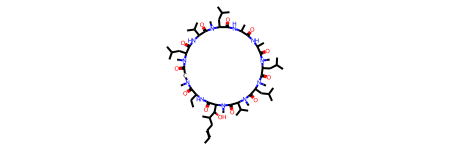

In [19]:
# Sample a random molecule from a list

import random
idx = random.randint(0, 1959)
# Using 1954
idx = 5
print(indexer_original_mols[5])
mols[idx]

In [54]:
next(i for i, n in enumerate(indexer_original_mols) if n == 'BS_0063')

165

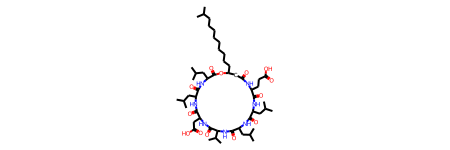

In [55]:
mols[165]

In [15]:
# helper functions to avoid typing the same thing over and over
def to_smiles(mol_tuple):
    return tuple(Chem.MolToSmiles(mol) for mol in mol_tuple)

def from_smiles(smiles_tuple):
    return tuple(Chem.MolFromSmiles(smiles) for smiles in smiles_tuple)

In [22]:
from itertools import chain
from rdkit import Chem
from rdkit.Chem import rdChemReactions
from rdkit.Chem import Draw
# rxn = rdChemReactions.ReactionFromSmarts('[C;!$(C([#7])[#7]):1](=[O:2])[#7;+0;!D1:3]>>(O[C:1]=[O:2].[#7:3])')
reacts = (mols[165],)
all_reactions = {}
all_products = []
for i, run_fragmentation in enumerate(reactionDefs):
    rxn = rdChemReactions.ReactionFromSmarts(run_fragmentation)
    products = rxn.RunReactants(reacts)
    if products:
        all_reactions[names[i]] = products
        all_products.append(products)
all_products = chain.from_iterable(all_products)

print(all_reactions)
# convert to smiles and back to keep only unique products
all_products_smiles = [to_smiles(mol_tuple) for mol_tuple in all_products]
all_products_unique = [from_smiles(smiles_tuple) for smiles_tuple in set(all_products_smiles)]
nProductSets = len(all_products_unique)
print("Number of unique product sets:",nProductSets)

# draw each product set on its own line
prod_tpl = tuple(chain(*all_products_unique))
# Draw.MolsToGridImage(prod_tpl,molsPerRow=1)
    
# Chem.MolToSmiles(products[0][0])
# prod_tpl
# products[0][0]


{'amideR': ((<rdkit.Chem.rdchem.Mol object at 0x7f27668bfd50>,), (<rdkit.Chem.rdchem.Mol object at 0x7f27668bfdb0>,), (<rdkit.Chem.rdchem.Mol object at 0x7f27668bfe10>,), (<rdkit.Chem.rdchem.Mol object at 0x7f27668bfe70>,), (<rdkit.Chem.rdchem.Mol object at 0x7f27668bfed0>,), (<rdkit.Chem.rdchem.Mol object at 0x7f27668bff30>,), (<rdkit.Chem.rdchem.Mol object at 0x7f27668bff90>,)), 'etherR': ((<rdkit.Chem.rdchem.Mol object at 0x7f2766822690>,), (<rdkit.Chem.rdchem.Mol object at 0x7f2766822510>,))}
Number of unique product sets: 8


In [16]:
def run_fragmentation(mol_to_fragment, rxn, fragments_aux):
    reactants = (mol_to_fragment, )
    products = rxn.RunReactants(reactants)
    if products:
        # "Clean" mol by transforming it to SMILES and back to mol
        smiles_aux = to_smiles(products[0])
        tpl_prod = from_smiles(smiles_aux)
        prod_fragments = Chem.GetMolFrags(tpl_prod[0], asMols=True)
        for prod_fragment in prod_fragments:
            fragments_aux = run_fragmentation(prod_fragment, rxn, fragments_aux)
    else:
        fragments_aux.append(mol_to_fragment)
    return fragments_aux

In [20]:
reaction_rule = '[C;!$(C([#7])[#7]):1](=[O:2])[#7;+0;!D1:3]>>(O[C:1]=[O:2].[#7:3])'
rxn = Reactions.ReactionFromSmarts(reaction_rule)
rtnts = (mols[165],)


In [74]:
fragments_aux = []
fragments_aux = run_fragmentation(mols[165], rxn, fragments_aux)
fragments_aux

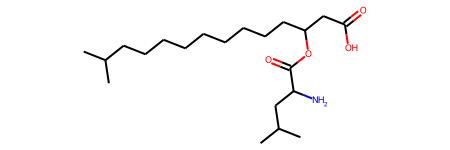

In [83]:
fragments_aux[6]

In [40]:
products = rxn.RunReactants(rtnts)
products

((<rdkit.Chem.rdchem.Mol at 0x7f4e7e6e6510>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f4eb0740b70>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f4eb0740990>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f4eb0740bd0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f4eb0740c30>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f4eb0740a50>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f4eb0740c90>,))

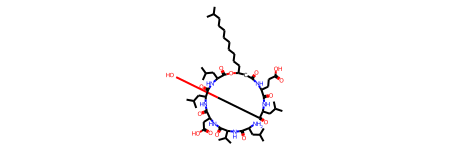

In [42]:
products[0][0]

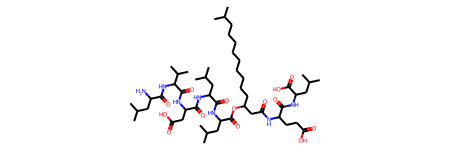

In [41]:
smiles_aux = to_smiles(products[0])
tpl_prod = from_smiles(smiles_aux)
Chem.GetMolFrags(tpl_prod[0], asMols=True)[0]

In [25]:
products2 = rxn.RunReactants(products[0])
products2

((<rdkit.Chem.rdchem.Mol at 0x7f2766829750>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2766829690>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f27668297b0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f27668298d0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2766829930>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2766829990>,))

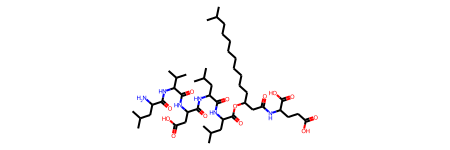

In [30]:
smiles_aux = to_smiles(products2[0])
tpl_prod = from_smiles(smiles_aux)
tpl_prod[0]
aux_mol = Chem.GetMolFrags(tpl_prod[0], asMols=True)[1]
aux_mol

In [31]:
products3 = rxn.RunReactants((aux_mol,))
products3

((<rdkit.Chem.rdchem.Mol at 0x7f276681cd50>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2766821270>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f27668211b0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2766821210>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f27668213f0>,))

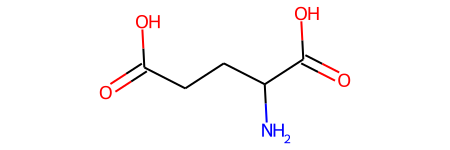

In [34]:
smiles_aux = to_smiles(products3[0])
tpl_prod = from_smiles(smiles_aux)
tpl_prod[0]
aux_mol = Chem.GetMolFrags(tpl_prod[0], asMols=True)[1]
aux_mol

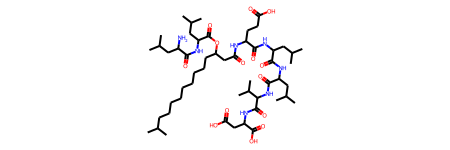

In [86]:
prod_tpl[0]

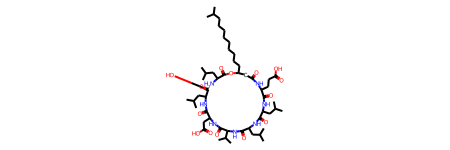

In [70]:
all_reactions['amideR'][2][0]

In [19]:
etheR_reactant = {'etherR': reactants['etherR']}
etheR_broken_bond = {'etherR': brokenBondsDefs['etherR']}

In [23]:
rxn_etherR = Reactions.ReactionFromSmarts(reactions['etherR'])

In [43]:
products_etherR = rxn_etherR.RunReactants((mols[165],))

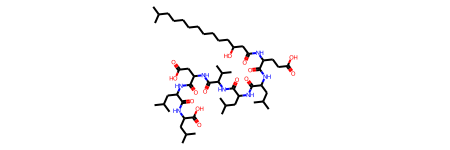

In [44]:
products_etherR[0][0]
smiles_aux = to_smiles(products_etherR[0])
tpl_prod = from_smiles(smiles_aux)
tpl_prod[0]
aux_mol = Chem.GetMolFrags(tpl_prod[0], asMols=True)[0]
aux_mol

In [45]:
products_etherR2 = rxn_etherR.RunReactants(products_etherR[0])
products_etherR2

()

### 1.5.1. Initialize the Geass fragmentator

In [48]:
# The verbose argument controls the number of messages shown.
# The ester reaction is still giving an error

# Explicar la automatizacion de los inputs.

fragmentator = geass.Geass(mols[165], etheR_broken_bond, etheR_reactant, reactionsMol2, fillingAtoms, df_lipids, verbose=0) # Lipidmaps
# fragmentator = geass.Geass(mols[idx], brokenBondsDefs, reactants, reactionsMol2, fillingAtoms, df_ids, verbose=0) # MetanetX + BUL (not currently working)
# fragmentator = geass.Geass(mols[165], brokenBondsDefs, reactants, reactionsMol2, fillingAtoms, BULnames, verbose=0) # Default Geass

### 1.5.2. Identify the bonds to break

In [49]:
fragmentator.get_bonds_to_break()

In [50]:
# You can explore the detected bonds and their type.

fragmentator.breakable_mol_bonds

{0: 'etherR'}

In [51]:
mol_f = Chem.FragmentOnBonds(mols[165], fragmentator.breakable_mol_bonds, addDummies=False)

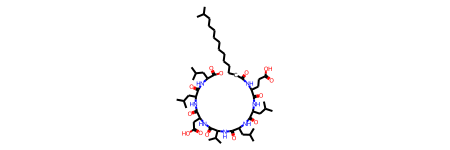

In [52]:
mol_f

In [166]:
fragmentator.mol_bonds

### 1.5.3. Creating the graph

In [43]:
# This function will create a graph (Networkx like) containing the fragments of the molecule
# TODO: Separate graph creation from actual fragmentation

fragmentator.create_fragmentation_graph()

In [46]:
fragmentator.fragments_filled

### 1.5.4. Plot the graph

In [45]:
# Nodes whose attribute 'isNP' is Yes will be plotted in green. Otherwise, in red.

fragmentator.plot_graph()

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

In [ ]:
graph_nodes = list(fragmentator.graph.nodes(data=True))
graph_nodes

In [206]:
graph_edges = list(fragmentator.graph.edges(data=True))
graph_edges

[(0, 3, {'reaction': 'amideR'}),
 (0, 4, {'reaction': 'etherR'}),
 (1, 2, {'reaction': 'amideR'}),
 (1, 5, {'reaction': 'amideR'}),
 (2, 6, {'reaction': 'amideR'}),
 (3, 7, {'reaction': 'amideR'}),
 (4, 5, {'reaction': 'amideR'}),
 (6, 7, {'reaction': 'amideR'})]

In [26]:
NP_fragments = [frag for frag in graph_nodes if frag[1]['isNP'] == 'Yes']
NP_fragments

[(10,
  {'SMILES': '[H]NC(C)C(=O)O',
   'img': 'data:image/svg+xml;charset=utf-8,%3C%3Fxml%20version%3D%271.0%27%20encoding%3D%27iso-8859-1%27%3F%3E%0A%3Csvg%20version%3D%271.1%27%20baseProfile%3D%27full%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3D%27http%3A%2F%2Fwww.w3.org%2F2000%2Fsvg%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Ardkit%3D%27http%3A%2F%2Fwww.rdkit.org%2Fxml%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Axlink%3D%27http%3A%2F%2Fwww.w3.org%2F1999%2Fxlink%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xml%3Aspace%3D%27preserve%27%0Awidth%3D%27350px%27%20height%3D%27300px%27%20viewBox%3D%270%200%20350%20300%27%3E%0A%3C%21--%20END%20OF%20HEADER%20--%3E%0A%3Crect%20style%3D%27opacity%3A1.0%3Bfill%3A%23FFFFFF%3Bstroke%3Anone%27%20width%3D%27350.0%27%20height%3D%27300.0%27%20x%3D%270.0%27%20y%3D%270.0%27%3E%20%3C%2Frect%3E%0A%3Cpath%20class%3D%27bond-0%20atom-0%20atom-1%27%20d%3D%27M%20278

In [80]:
not_NP_fragments = {frag[0]: frag[1]['SMILES'] for frag in graph_nodes if frag[1]['isNP'] == 'No'}
not_NP_fragments

{0: '[H]N([H])C(C(=O)O)C(O)C(C)CC',
 1: '[H]N([H])C(C=O)C(C)C',
 2: '[H]N([H])C(C=O)CC(C)C',
 3: '[H]N([H])C(C=O)CC(C)C',
 4: '[H]NC(C)C=O',
 5: '[H]NC(C=O)C(C)C',
 6: '[H]NC(C=O)CC',
 15: 'CC'}

# 2. Run Metabolic Disassembler

In [22]:
# Loads the PBU

with open('metadisassembler5/data/PBU_v2.pkl', 'rb') as f:
    PBU = pickle.load(f)

In [23]:
# Loads the BUL

with open('metadisassembler5/data/BUL_Mar23.pkl', 'rb') as f:
    BULv2 = pickle.load(f)

In [24]:
fails = []
indexer = {}
results = {}
fragments = {}
fragment_names = {}
n_samples = len(mols)

# -------------------------- Generate the query_specific_bul (qsu) -----------------------------------

# We first compute the query_specific_bul. We save it for later computations. The results obtained 
# from this configuration are not expected to provide good results, only to provide an initialization
# step that saves computational times.

temp_qsu={} # The qsu are saved in this auxiliar memory.


for j, molecule_smiles in not_NP_fragments.items():
    # Iterate over the molecules 
    
    clear_output()
    print(f'PROGRESS: [{j+1}/{len(not_NP_fragments)}]')
    print(f'SMILES: {molecule_smiles}')
    
    disassembler = medi5.MetaDisassembler5() # Init the disassembler
    disassembler.output_folder = "./metadisassembler_v3_results" # Choose the output folder
    disassembler.useChirality = False # Whether to use Chilarity. IT HAS NOT BEEN TESTED IN 'TRUE' MODE
    disassembler.pbu = PBU # Assign the pbu
    disassembler.bul = BULv2 # Assign the bul
    disassembler.precomputed_qsu = False # We are not computed the qsu yet.
    disassembler.n_img = 1 
    disassembler.time_limit = 1
    name = str(j) + '_' + indexer_original_mols[idx]  # The name of the molecule
    molecule = Chem.MolFromSmiles(molecule_smiles) # The molecule from the current SMILES
    disassembler.input_molecule(molecule, name) # Define the input with the molecular structure and the name
     
    try:
        disassembler.disassemble() # disassemble
        indexer[j] = disassembler.name
        results[j] = disassembler.result
        temp_qsu[j] = disassembler.query_specific_bul # IMPORTANT: SAVE THE QSU
        fragment_names[j] = [disassembler.query_specific_bul.names[disassembler.match_bu_idx[k]] for aux, k in enumerate(disassembler.result[0]["target"])]
        fragments[j] = [disassembler.query_specific_bul.cpds[disassembler.match_bu_idx[k]] for aux, k in enumerate(disassembler.result[0]["target"])]
    except:
        print('Error')
        indexer[j] = 'Error'
        results[j] = 'Error'
        temp_qsu[j] = 'Error'
        fragment_names[j] = 'Error'

    
    if len(disassembler.result) == 0:
        fails.append(True)
    else:
        fails.append(False)
    

PROGRESS: [3/1]
SMILES: CC(C)CCCCCC(=O)O
Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
Len seed_list before optimising: 1
Finished.


In [25]:
fragment_names

{2: [['C06423'], ['C01438']]}

# 3. Add the new nodes and edges to the Geass graph

In [26]:
for not_NP_index in not_NP_fragments:
    # Creating new nodes list
    previous_graph_length = len(fragmentator.graph.nodes)
    new_nodes = [(i + previous_graph_length, {'SMILES': Chem.MolToSmiles(frag_mol.mol), 'img': geass.smi2image(Chem.MolToSmiles(frag_mol.mol)), 'isNP': 'Yes', 'kegg_id': fragment_names[not_NP_index][i][0]}) for i, frag_mol in enumerate(fragments[not_NP_index])]
    # Adding the nodes to the Geass graph
    fragmentator.graph.add_nodes_from(new_nodes)

    # Creating new edges list
    new_edges = []
    for fragment_index in range(len(fragments[not_NP_index])):
        new_edges.append((not_NP_index, fragment_index + previous_graph_length, {'reaction': 'unknown'}))
    # Adding the edges to the Geass graph
    fragmentator.graph.add_edges_from(new_edges)

In [27]:
graph_nodes = list(fragmentator.graph.nodes(data=True))
graph_nodes

[(0,
  {'SMILES': 'O=C(O)CC(O)(CC(=O)O)C(=O)O',
   'img': 'data:image/svg+xml;charset=utf-8,%3C%3Fxml%20version%3D%271.0%27%20encoding%3D%27iso-8859-1%27%3F%3E%0A%3Csvg%20version%3D%271.1%27%20baseProfile%3D%27full%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3D%27http%3A%2F%2Fwww.w3.org%2F2000%2Fsvg%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Ardkit%3D%27http%3A%2F%2Fwww.rdkit.org%2Fxml%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Axlink%3D%27http%3A%2F%2Fwww.w3.org%2F1999%2Fxlink%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xml%3Aspace%3D%27preserve%27%0Awidth%3D%27350px%27%20height%3D%27300px%27%20viewBox%3D%270%200%20350%20300%27%3E%0A%3C%21--%20END%20OF%20HEADER%20--%3E%0A%3Crect%20style%3D%27opacity%3A1.0%3Bfill%3A%23FFFFFF%3Bstroke%3Anone%27%20width%3D%27350.0%27%20height%3D%27300.0%27%20x%3D%270.0%27%20y%3D%270.0%27%3E%20%3C%2Frect%3E%0A%3Cpath%20class%3D%27bond-0%20atom-0%20atom-1%27%20d%3

In [28]:
fragmentator.graph.edges(data=True)

EdgeDataView([(0, 1, {'reaction': 'amideR'}), (1, 2, {'reaction': 'amideR'}), (2, 3, {'reaction': 'unknown'}), (2, 4, {'reaction': 'unknown'})])

In [29]:
# Plot the graph again
fragmentator.plot_graph()

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

# 4. Run the process with all the compounds

In [30]:
start_time = time.time()
result_graphs = {}
disassembled_ids = {}

# Lists to analyze results
fragmented_all_NP = set()
fragmented_not_NP_OK = set()
fragmented_not_NP_ERROR = set()
not_fragmented_all_NP = set()
not_fragmented_not_NP_OK = set()
not_fragmented_not_NP_ERROR = set()

for mol_idx, current_mol in enumerate(mols):
    clear_output()
    print(f'PROGRESS: [{mol_idx+1}/{len(mols)}]')
    # Initialize Geass
    fragmentator = geass.Geass(current_mol, brokenBondsDefs, reactants, fillingAtoms, BULnames, verbose=0)

    # Get bonds to break
    fragmentator.get_bonds_to_break()
    
    # Create graph
    fragmentator.create_fragmentation_graph()
    
    # Get not NP fragments
    graph_nodes = list(fragmentator.graph.nodes(data=True))
    not_NP_fragments = {frag[0]: frag[1]['SMILES'] for frag in graph_nodes if frag[1]['isNP'] == 'No'}
    
    fragments = {}
    fragment_names = {}
    
    # Run metabolic disassembler
    for j, molecule_smiles in not_NP_fragments.items():
        # Iterate over the molecules 

        disassembler = medi5.MetaDisassembler5() # Init the disassembler
        disassembler.output_folder = "./metadisassembler_v3_results" # Choose the output folder
        disassembler.useChirality = False # Whether to use Chilarity. IT HAS NOT BEEN TESTED IN 'TRUE' MODE
        disassembler.pbu = PBU # Assign the pbu
        disassembler.bul = BULv2 # Assign the bul
        disassembler.precomputed_qsu = False # We are not computed the qsu yet.
        disassembler.n_img = 1 
        disassembler.time_limit = 1
        name = str(j) + '_' + indexer_original_mols[mol_idx]  # The name of the molecule
        molecule = Chem.MolFromSmiles(molecule_smiles) # The molecule from the current SMILES
        disassembler.input_molecule(molecule, name) # Define the input with the molecular structure and the name

        try:
            disassembler.disassemble() # disassemble
            #indexer[j] = disassembler.name
            #results[j] = disassembler.result
            #temp_qsu[j] = disassembler.query_specific_bul # IMPORTANT: SAVE THE QSU
            fragment_names[j] = [disassembler.query_specific_bul.names[disassembler.match_bu_idx[k]] for aux, k in enumerate(disassembler.result[0]["target"])]
            fragments[j] = [disassembler.query_specific_bul.cpds[disassembler.match_bu_idx[k]] for aux, k in enumerate(disassembler.result[0]["target"])]
        except:
            print('Error')
            #indexer[j] = 'Error'
            #results[j] = 'Error'
            #temp_qsu[j] = 'Error'
            fragments[j] = 'Error'
            fragment_names[j] = 'Error'

        #if len(disassembler.result) == 0:
            #fails.append(True)
        #else:
            #fails.append(False)
    # Add the Kegg ids to the id list of current compound
    disassembled_ids[indexer_original_mols[mol_idx]] = []
    for names in fragment_names.values():
        if names != 'Error':
            disassembled_ids[indexer_original_mols[mol_idx]] = disassembled_ids[indexer_original_mols[mol_idx]] + names
        else:
            # ADD [Error]
            pass
    if fragments:
        if 'Error' not in fragments.values():
            # Add new nodes and edges
            for not_NP_index in not_NP_fragments:
                # Creating new nodes list
                previous_graph_length = len(fragmentator.graph.nodes)
                new_nodes = [(i + previous_graph_length, {'SMILES': Chem.MolToSmiles(frag_mol.mol), 'img': geass.smi2image(Chem.MolToSmiles(frag_mol.mol)), 'isNP': 'Yes', 'kegg_id': fragment_names[not_NP_index][i][0]}) for i, frag_mol in enumerate(fragments[not_NP_index])]
                # Adding the nodes to the Geass graph
                fragmentator.graph.add_nodes_from(new_nodes)

                # Creating new edges list
                new_edges = []
                for fragment_index in range(len(fragments[not_NP_index])):
                    new_edges.append((not_NP_index, fragment_index + previous_graph_length, {'reaction': 'unknown'}))
                # Adding the edges to the Geass graph
                fragmentator.graph.add_edges_from(new_edges)
            # Add compound to corresponding no NP OK analytics list
            if len(graph_nodes) == 1:
                not_fragmented_not_NP_OK.add(indexer_original_mols[mol_idx])
            else:
                fragmented_not_NP_OK.add(indexer_original_mols[mol_idx])
        else:
            # Add compound to corresponding no NP ERROR analytics list
            if len(graph_nodes) == 1:
                not_fragmented_not_NP_ERROR.add(indexer_original_mols[mol_idx])
            else:
                fragmented_not_NP_ERROR.add(indexer_original_mols[mol_idx])
    else:
        # Add compound to corresponding NP analytics list
        if len(graph_nodes) == 1:
            not_fragmented_all_NP.add(indexer_original_mols[mol_idx])
        else:
            fragmented_all_NP.add(indexer_original_mols[mol_idx])
    # Add the graph to the result graph list
    result_graphs[indexer_original_mols[mol_idx]] = fragmentator
print(f"Elapsed: {round(time.time() - start_time, 3)}s")

PROGRESS: [1853/1853]
No breakable bonds were found. Impossible to create the fragmentation graph.
Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
Over the time limit. Computation time: 1
No results.
Error
Elapsed: 987.891s


RDKit WARNING: [14:02:08] WARNING: Omitted undefined stereo
mitted undefined stereo
[14:02:08] WARNING: Omitted undefined stereo
[14:02:08] WARNING: Omitted undefined stereo
[14:02:08] WARNING: Omitted undefined stereo
[14:02:08] WARNING: Omitted undefined stereo
[14:02:09] WARNING: Omitted undefined stereo
[14:02:09] WARNING: Omitted undefined stereo
[14:02:09] WARNING: Omitted undefined stereo
[14:02:09] WARNING: Omitted undefined stereo
[14:02:09] WARNING: Omitted undefined stereo
[14:02:09] WARNING: Omitted undefined stereo
[14:02:09] WARNING: Omitted undefined stereo
[14:02:09] WARNING: Omitted undefined stereo
[14:02:09] WARNING: Omitted undefined stereo
[14:02:10] WARNING: Omitted undefined stereo
[14:02:10] WARNING: Omitted undefined stereo
[14:02:10] WARNING: Omitted undefined stereo
[14:02:10] WARNING: Omitted undefined stereo
[14:02:10] WARNING: Omitted undefined stereo
[14:02:10] WARNING: Omitted undefined stereo
[14:02:10] WARNING: Omitted undefined stereo
[14:02:11] WARNI

In [31]:
analytics_df = pd.DataFrame()
analytics_df['Fragmented All NP'] = list(fragmented_all_NP)
analytics_df = pd.concat([analytics_df, pd.DataFrame({'Fragmented not NP OK': list(fragmented_not_NP_OK)})], axis=1)
analytics_df = pd.concat([analytics_df, pd.DataFrame({'Fragmented not NP ERROR': list(fragmented_not_NP_ERROR)})], axis=1)
analytics_df = pd.concat([analytics_df, pd.DataFrame({'Not fragmented All NP': list(not_fragmented_all_NP)})], axis=1)
analytics_df = pd.concat([analytics_df, pd.DataFrame({'Not fragmented not NP OK': list(not_fragmented_not_NP_OK)})], axis=1)
analytics_df = pd.concat([analytics_df, pd.DataFrame({'Not fragmented not NP ERROR': list(not_fragmented_not_NP_ERROR)})], axis=1)

In [32]:
analytics_df

,Fragmented All NP,Fragmented not NP OK,Fragmented not NP ERROR,Not fragmented All NP,Not fragmented not NP OK,Not fragmented not NP ERROR
0,BS_0810,SF_0207,BS_0328,SF_0298,BS_0502,BS_1057
1,BS_0802,BS_0230,BS_0656,BS_0894,BS_1440,BS_0413
2,SF_0458,BS_1380,BS_0681,SF_0196,BS_0031,BS_1070
3,BS_1081,SF_0649,BS_0611,BS_0906,BS_0381,BS_0571
4,SF_0217,SF_0647,BS_0757,BS_1195,SF_0602,SF_0700
...,...,...,...,...,...,...
1123,NaN,SF_0060,NaN,NaN,NaN,NaN
1124,NaN,BS_1566,NaN,NaN,NaN,NaN
1125,NaN,BS_0828,NaN,NaN,NaN,NaN
1126,NaN,BS_0366,NaN,NaN,NaN,NaN


In [33]:
# analytics_df.to_csv("geass_and_MD_analytics.csv", index=False)

In [34]:
# list(result_graphs['BS_1574'].graph.edges(data=True))

In [81]:
result_graphs['BS_1574'].plot_graph()

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

In [36]:
compound_edges = {}
for shared_name, rg in result_graphs.items():
    current_edges = []
    #print(shared_name)
    for edge in list(rg.graph.edges(data=True)):
        current_kegg_id_0 = rg.graph.nodes[edge[0]]['kegg_id']
        current_kegg_id_1 = rg.graph.nodes[edge[1]]['kegg_id']
        if current_kegg_id_0 == 'NA':
            edge0name = rg.get_all_NA_neighbours_names(edge[0])
        else:
            edge0name = current_kegg_id_0[0] if type(current_kegg_id_0) == tuple else current_kegg_id_0
        if current_kegg_id_1 == 'NA':
            edge1name = rg.get_all_NA_neighbours_names(edge[1])
        else:
            edge1name = current_kegg_id_1[0] if type(current_kegg_id_1) == tuple else current_kegg_id_1
        current_edges.append((edge0name, edge1name, edge[2]['reaction']))
    compound_edges[shared_name] = tuple(current_edges)

In [37]:
# Create dictionary with compounds and their edges
# compound_edges = {shared_name: [[edge[0], edge[1], edge[2]['reaction']] for edge in list(geass_obj.graph.edges(data=True))] for shared_name, geass_obj in result_graphs.items()}

In [38]:
compound_edges

{'SF_0293': (),
 'SF_0298': (),
 'SF_0446': (),
 'SF_0197': (('C00065', 'C00065', 'etherR'),
  ('C00065', 'C00065', 'etherR'),
  ('C00065', 'C00196', 'amideR'),
  ('C00065', 'C00065', 'etherR'),
  ('C00065', 'C00196', 'amideR'),
  ('C00065', 'C00196', 'amideR')),
 'BS_0894': (),
 'BS_1574': (('', '', 'laNalC'),
  ('', '', 'amideR'),
  ('', 'C00132', 'cyclicAmines'),
  ('', '', 'olefin'),
  ('', '', 'laNalC'),
  ('', 'C00132', 'cyclicAmines'),
  ('', '', 'laNalC'),
  ('', 'C00132', 'cyclicAmines'),
  ('', '', 'laNalC'),
  ('', 'C00132', 'cyclicAmines'),
  ('', 'C00041', 'amideR'),
  ('', 'C00123', 'amideR'),
  ('', 'C00123', 'laNalC'),
  ('', 'C00037_mod_0', 'laNalC'),
  ('C00123', 'C00037_mod_0', 'laNalC'),
  ('C00123', 'C00132', 'cyclicAmines'),
  ('C00123', 'C00041', 'amideR'),
  ('C00123', 'C00132', 'cyclicAmines'),
  ('C00037_mod_0', 'C00132', 'cyclicAmines')),
 'SF_0068': (('C01672+C00001', 'C00042', 'amideR'),
  ('C01672+C00001', 'C00042', 'amideR'),
  ('C01672+C00001', 'C01672',

In [39]:
'''
csv_string = 'ID_UNIQUE,"Compounds ids"\n'
for k, v in disassembled_ids.items():
    csv_string += k + ',"' + str(v) + '"\n'
with open('dissasembled.csv', 'w') as csv_file:
    csv_file.write(csv_string)
'''

'\ncsv_string = \'ID_UNIQUE,"Compounds ids"\n\'\nfor k, v in disassembled_ids.items():\n    csv_string += k + \',"\' + str(v) + \'"\n\'\nwith open(\'dissasembled.csv\', \'w\') as csv_file:\n    csv_file.write(csv_string)\n'

In [40]:
def jaccard_similarity(g, h):
    #i = set(g).intersection(h)
    if len(g) == 0 or len(h) == 0:
        return 0
    i = list((Counter(g) & Counter(h)).elements())
    divider = len(g) + len(h) - len(i)
    return round(len(i) / divider,3)

In [41]:
start = time.time()
similarity_matrix = []
for i, sent_i in enumerate(compound_edges.values()):
    templist = []
    for j, sent_j in enumerate(compound_edges.values()):
        #templist.append(geass.jaccard_similarity(sent_i, sent_j))
        if i == j:
            templist.append(1)
        else:
            templist.append(jaccard_similarity(sent_i, sent_j))
    similarity_matrix.append(templist)
similarity_df = pd.DataFrame(similarity_matrix, index=list(compound_edges.keys()), columns=list(compound_edges.keys()))
print(f"Elapsed: {round(time.time() - start, 3)}s")

Elapsed: 46.202s


In [222]:
similarity_df

,SF_0293,SF_0298,SF_0446,SF_0197,BS_0894,BS_1574,SF_0068,SF_0401,BS_1033,BS_0042,...,SF_0707,SF_0713,SF_0708,SF_0716,SF_0706,SF_0692,SF_0690,SF_0719,SF_0714,SF_0681
SF_0293,1,0,0,0.0,0,0.0,0.0,0.000,0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0
SF_0298,0,1,0,0.0,0,0.0,0.0,0.000,0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0
SF_0446,0,0,1,0.0,0,0.0,0.0,0.000,0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0
SF_0197,0,0,0,1.0,0,0.0,0.0,0.000,0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0
BS_0894,0,0,0,0.0,1,0.0,0.0,0.000,0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SF_0692,0,0,0,0.0,0,0.0,0.0,0.062,0,0.0,...,0.062,0.056,0.062,0.000,0.062,1.000,0.692,0.0,0.062,0
SF_0690,0,0,0,0.0,0,0.0,0.0,0.062,0,0.0,...,0.062,0.056,0.062,0.000,0.062,0.692,1.000,0.0,0.062,0
SF_0719,0,0,0,0.0,0,0.0,0.0,0.000,0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0
SF_0714,0,0,0,0.0,0,0.0,0.0,0.714,0,0.0,...,0.714,0.556,0.714,0.056,0.333,0.062,0.062,0.0,1.000,0


In [182]:
#similarity_df.to_csv('similarity_matrixv4.csv')

In [70]:
# TESTS
def plot_graph(graph):
    undirected = ipycytoscape.CytoscapeWidget()
    undirected.layout.height = '800px'
    undirected.layout.width = '970px'
    undirected.graph.add_graph_from_networkx(graph, directed=False)

    undirected.set_layout(name='circle', nodeSpacing=200, edgeLengthVal=100)
    undirected.set_style([{'selector': "node[isNP = 'Yes']", 'css': {
        'content': 'data(count)',
        'text-valign': 'top',
        'color': 'black',
        'text-outline-width': 2,
        'text-outline-color': '#FFFFFF',
        'shape': 'rectangle',
        'width': 400,
        'height': 350,
        'border-width': 20,
        'border-color': '#08d13e',
        'background-color': '#FFFFFF',
        'background-fit': 'contain',
        'background-image': 'data(img)',
        'label': 'data(kegg_id)'}},

                          {'selector': "node[isNP = 'No']", 'css': {
                              'content': 'data(count)',
                              'text-valign': 'top',
                              'color': 'white',
                              'text-outline-width': 2,
                              'curve-style': 'straight',
                              'text-outline-color': '#FFFFFF',
                              'shape': 'rectangle',
                              'width': 400,
                              'height': 350,
                              'border-width': 20,
                              'border-color': '#d10808',
                              'background-color': '#FFFFFF',
                              'background-fit': 'contain',
                              'background-image': 'data(img)'}},
                          {'selector': "edge", 'css': {
                              "curve-style": "bezier",
                              'width': 20,
                              'label': 'data(reaction)',
                              'line-color': '#08d13e', }},
                          {'selector': "edge[reaction='unknown']", 'css': {
                              'line-color': '#d10808', }},
                              ])
    return undirected

In [48]:
# TESTS
plot_graph(result_graphs['BS_0008'].graph)

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

In [49]:
# TESTS
plot_graph(result_graphs['BS_0026'].graph)

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

In [172]:
# TESTS
#list((Counter(compound_edges['SF_0293']) & Counter(compound_edges['SF_0298'])).elements())
Counter(compound_edges['SF_0293'])

Counter()

In [51]:
# TESTS
jaccard_similarity(compound_edges['BS_0008'], compound_edges['BS_0026'])

0.062

In [52]:
# TESTS
# test_graph = nx.compose_all([result_graphs['BS_0008'].graph, result_graphs['BS_0026'].graph, result_graphs['BS_0011'].graph])
test_graph = nx.compose(result_graphs['BS_0008'].graph, result_graphs['BS_0026'].graph)

plot_graph(test_graph)

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

In [53]:
# TESTS
for edge in test_graph.edges():
    if not result_graphs['BS_0008'].graph.has_edge(*edge):
        print(f'Has no edge {edge}')
        
test_nodes = set(result_graphs['BS_0008'].graph.nodes())

for node in test_graph.nodes():
    if node not in test_nodes:
        print(f'Has no node {node}')

aux_graph = test_graph.copy()

aux_graph.remove_nodes_from(n for n in test_graph if n not in result_graphs['BS_0008'].graph)
aux_graph.remove_edges_from(e for e in test_graph.edges if e not in result_graphs['BS_0008'].graph.edges)

plot_graph(aux_graph)

Has no edge (2, 8)
Has no edge (3, 4)
Has no edge (3, 6)
Has no edge (4, 5)
Has no edge (6, 7)
Has no edge (8, 9)
Has no edge (8, 10)
Has no node 7
Has no node 8
Has no node 9
Has no node 10


CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

In [54]:
# TESTS
# Create some sample graphs
# G1 = nx.Graph()
# G1.add_node('A', color='red')
# G1.add_node('B', color='green')
# G1.add_edge('A', 'B')

# G2 = nx.Graph()
# G2.add_node('A', color='blue')
# G2.add_node('B', color='green')
# G2.add_edge('A', 'B')

# # Compute the intersection of the graphs
# graphs = [G1, G2]
# intersection = nx.intersection_all([result_graphs['BS_0008'].graph, result_graphs['BS_0026'].graph, result_graphs['BS_0011'].graph])

# # Print the resulting intersection
# print(intersection.nodes(data=True))
# print(intersection.edges())
# plot_graph(intersection)

In [55]:
# TESTS
# Counter(list(result_graphs['BS_0008'].graph.nodes(data=True)))

In [56]:
# TESTS
result_graphs['BS_0008'].graph.nodes[0]

{'SMILES': 'CC(O)CCCCCC/C=C\\CCCCCCCC(=O)O',
 'img': 'data:image/svg+xml;charset=utf-8,%3C%3Fxml%20version%3D%271.0%27%20encoding%3D%27iso-8859-1%27%3F%3E%0A%3Csvg%20version%3D%271.1%27%20baseProfile%3D%27full%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3D%27http%3A%2F%2Fwww.w3.org%2F2000%2Fsvg%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Ardkit%3D%27http%3A%2F%2Fwww.rdkit.org%2Fxml%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Axlink%3D%27http%3A%2F%2Fwww.w3.org%2F1999%2Fxlink%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xml%3Aspace%3D%27preserve%27%0Awidth%3D%27350px%27%20height%3D%27300px%27%20viewBox%3D%270%200%20350%20300%27%3E%0A%3C%21--%20END%20OF%20HEADER%20--%3E%0A%3Crect%20style%3D%27opacity%3A1.0%3Bfill%3A%23FFFFFF%3Bstroke%3Anone%27%20width%3D%27350.0%27%20height%3D%27300.0%27%20x%3D%270.0%27%20y%3D%270.0%27%3E%20%3C%2Frect%3E%0A%3Cpath%20class%3D%27bond-0%20atom-0%20atom-1%27%20d%3D%27M

In [57]:
# TESTS
[a for n, a in result_graphs['BS_0008'].graph.nodes(data=True)]

[{'SMILES': 'CC(O)CCCCCC/C=C\\CCCCCCCC(=O)O',
  'img': 'data:image/svg+xml;charset=utf-8,%3C%3Fxml%20version%3D%271.0%27%20encoding%3D%27iso-8859-1%27%3F%3E%0A%3Csvg%20version%3D%271.1%27%20baseProfile%3D%27full%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3D%27http%3A%2F%2Fwww.w3.org%2F2000%2Fsvg%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Ardkit%3D%27http%3A%2F%2Fwww.rdkit.org%2Fxml%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Axlink%3D%27http%3A%2F%2Fwww.w3.org%2F1999%2Fxlink%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xml%3Aspace%3D%27preserve%27%0Awidth%3D%27350px%27%20height%3D%27300px%27%20viewBox%3D%270%200%20350%20300%27%3E%0A%3C%21--%20END%20OF%20HEADER%20--%3E%0A%3Crect%20style%3D%27opacity%3A1.0%3Bfill%3A%23FFFFFF%3Bstroke%3Anone%27%20width%3D%27350.0%27%20height%3D%27300.0%27%20x%3D%270.0%27%20y%3D%270.0%27%3E%20%3C%2Frect%3E%0A%3Cpath%20class%3D%27bond-0%20atom-0%20atom-1%27%20d%3D%2

In [58]:
# TESTS
node_set = set(frozenset(a) for n, a in result_graphs['BS_0008'].graph.nodes(data=True))
node_set.intersection(set(frozenset(a) for n, a in result_graphs['BS_0026'].graph.nodes(data=True)))

{frozenset({'SMILES', 'img', 'isNP', 'kegg_id'})}

In [60]:
# TESTS
G = [a for n, a in result_graphs['BS_0008'].graph.nodes(data=True)]
H = [a for n, a in result_graphs['BS_0026'].graph.nodes(data=True)]
GH = []

for n in G:
    if n in H:
        GH.append(n)
        H.remove(n)
GH

[{'SMILES': '[H]OC1C(CO)OC(O)C(O)C1O',
  'img': 'data:image/svg+xml;charset=utf-8,%3C%3Fxml%20version%3D%271.0%27%20encoding%3D%27iso-8859-1%27%3F%3E%0A%3Csvg%20version%3D%271.1%27%20baseProfile%3D%27full%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3D%27http%3A%2F%2Fwww.w3.org%2F2000%2Fsvg%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Ardkit%3D%27http%3A%2F%2Fwww.rdkit.org%2Fxml%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Axlink%3D%27http%3A%2F%2Fwww.w3.org%2F1999%2Fxlink%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xml%3Aspace%3D%27preserve%27%0Awidth%3D%27350px%27%20height%3D%27300px%27%20viewBox%3D%270%200%20350%20300%27%3E%0A%3C%21--%20END%20OF%20HEADER%20--%3E%0A%3Crect%20style%3D%27opacity%3A1.0%3Bfill%3A%23FFFFFF%3Bstroke%3Anone%27%20width%3D%27350.0%27%20height%3D%27300.0%27%20x%3D%270.0%27%20y%3D%270.0%27%3E%20%3C%2Frect%3E%0A%3Cpath%20class%3D%27bond-0%20atom-0%20atom-1%27%20d%3D%27M%2014

In [68]:
# TESTS SF_0148 SF_0516
def get_graph_intersection(G_graph, H_graph):
    G_nodes = [n for n in G_graph.graph.nodes(data=True)]
    H_nodes = [n for n in H_graph.graph.nodes(data=True)]
    G_edges = [e for e in G_graph.graph.edges(data=True)]
    H_edges = [e for e in H_graph.graph.edges(data=True)]

    # asdf = [(G_graph.graph.nodes[e[0]], G_graph.graph.nodes[e[1]], e[2]) for e in G_graph.graph.edges(data=True)]
    G_edges_intersected = []
    H_edges_intersected = []

    for e1 in G_edges:
        source1_idx = e1[0]
        source1 = G_graph.graph.nodes[source1_idx]['kegg_id'] if G_graph.graph.nodes[source1_idx]['kegg_id'] != 'NA' else G_graph.get_all_NA_neighbours_names(source1_idx)
        target1_idx = e1[1]
        target1 = G_graph.graph.nodes[target1_idx]['kegg_id'] if G_graph.graph.nodes[target1_idx]['kegg_id'] != 'NA' else G_graph.get_all_NA_neighbours_names(target1_idx)
        reaction1 = e1[2]
        for e2 in H_edges:
            source2_idx = e2[0]
            source2 = H_graph.graph.nodes[source2_idx]['kegg_id'] if H_graph.graph.nodes[source2_idx]['kegg_id'] != 'NA' else H_graph.get_all_NA_neighbours_names(source2_idx)
            target2_idx = e2[1]
            target2 = H_graph.graph.nodes[target2_idx]['kegg_id'] if H_graph.graph.nodes[target2_idx]['kegg_id'] != 'NA' else H_graph.get_all_NA_neighbours_names(target2_idx)
            reaction2 = e2[2]
            if (source1 == source2 and target1 == target2 or source1==target2 and target1 == source2) and reaction1 == reaction2:
                G_edges_intersected.append((source1_idx, target1_idx))
                H_edges_intersected.append((source2_idx, target2_idx))
                H_edges.remove(e2)
                break
                
    G_nodes_intersected = set(item for sublist in G_edges_intersected for item in sublist)
    H_nodes_intersected = set(item for sublist in H_edges_intersected for item in sublist)
    print(G_edges_intersected)
    print(G_nodes_intersected)
    print(H_edges_intersected)
    print(H_nodes_intersected)

    G_nodes = [x for x in G_nodes if x[0] not in G_nodes_intersected]
    H_nodes = [x for x in H_nodes if x[0] not in H_nodes_intersected]
    # node = (i, {attr1: val1, attr2: val2})

    for ng in G_nodes:
        for nh in H_nodes:
            if ng[1]['kegg_id'] == nh[1]['kegg_id']:
                G_nodes_intersected.add(ng[0])
                H_nodes_intersected.add(nh[0])
                H_nodes.remove(nh)
                break

    print(G_nodes_intersected)
    print(H_nodes_intersected)

    G_nodes_aux = list(G_nodes_intersected)
    G_nodes_aux.sort()
    print(G_nodes_aux)
    
    # Creating the result graph
    intersection_graph = nx.Graph()
    intersection_graph.add_nodes_from([(new_id, G_graph.graph.nodes[n_id]) for new_id, n_id in enumerate(G_nodes_aux)])
    intersection_graph.add_edges_from([(G_nodes_aux.index(e[0]), G_nodes_aux.index(e[1]), G_graph.graph.edges[e]) for e in G_edges_intersected])
    return intersection_graph
intersection_graph = get_graph_intersection(result_graphs['SF_0148'], result_graphs['SF_0516'])

[(0, 4), (0, 6), (0, 7), (1, 4), (1, 5), (1, 8), (1, 9), (3, 5), (3, 10), (3, 11)]
{0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11}
[(1, 3), (1, 7), (1, 8), (1, 4), (2, 4), (2, 9), (2, 10), (3, 5), (5, 11), (5, 12)]
{1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12}
{0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11}
{1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12}
[0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11]


In [71]:
plot_graph(intersection_graph)

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

In [50]:
result_graphs['SF_0148'].plot_graph()

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

In [85]:
indexer_original_mols[28]

'SF_0516'

In [109]:
PBU_mols = {code: Chem.MolFromInchi(x) for code, x in PBU.items()}

In [110]:
PBU_mols

{'C00577': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6d750>,
 'C02426': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6d030>,
 'C01796': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6df30>,
 'C06463': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6db70>,
 'C00216': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6da50>,
 'C00259': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6d5d0>,
 'C00181': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6dbd0>,
 'C01510': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6dcf0>,
 'C00476': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6dd50>,
 'C01508': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6dc30>,
 'C00121': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6dc90>,
 'C00031': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6de10>,
 'C00124': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6de70>,
 'C01825': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6ded0>,
 'C00159': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6d6f0>,
 'C01487': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6d0f0>,
 'C06464': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6d9f0>,
 'C06465': <rdkit.Chem.rdchem.Mol at 0x7f9c1aa6d150>,
 'C15923': <rdkit.Chem.rdche

In [105]:
BULnames

{('C00001',): <rdkit.Chem.rdchem.Mol at 0x7f9cc82c9ef0>,
 ('C00002',): <rdkit.Chem.rdchem.Mol at 0x7f9ca71be2f0>,
 ('C00003',): <rdkit.Chem.rdchem.Mol at 0x7f9c9aa6a0f0>,
 ('C00004',): <rdkit.Chem.rdchem.Mol at 0x7f9c9d6ed8f0>,
 ('C00005',): <rdkit.Chem.rdchem.Mol at 0x7f9c9aa6a1b0>,
 ('C00006',): <rdkit.Chem.rdchem.Mol at 0x7f9c9aa6a230>,
 ('C00007',): <rdkit.Chem.rdchem.Mol at 0x7f9c9aa53a70>,
 ('C00008',): <rdkit.Chem.rdchem.Mol at 0x7f9c9aa7e8f0>,
 ('C00009',): <rdkit.Chem.rdchem.Mol at 0x7f9c9aa7e930>,
 ('C00010',): <rdkit.Chem.rdchem.Mol at 0x7f9c9aa7ef30>,
 ('C00011',): <rdkit.Chem.rdchem.Mol at 0x7f9ca78e33f0>,
 ('C00013',): <rdkit.Chem.rdchem.Mol at 0x7f9c9871b0f0>,
 ('C00014',): <rdkit.Chem.rdchem.Mol at 0x7f9c9871b1f0>,
 ('C00015',): <rdkit.Chem.rdchem.Mol at 0x7f9c9871b2f0>,
 ('C00016',): <rdkit.Chem.rdchem.Mol at 0x7f9c9871b3f0>,
 ('C00018',): <rdkit.Chem.rdchem.Mol at 0x7f9c9871b4f0>,
 ('C00019',): <rdkit.Chem.rdchem.Mol at 0x7f9c9871b5f0>,
 ('C00020',): <rdkit.Chem.rdche

In [103]:
BUL_geass = list(BULnames.keys())
PBU_MD = list(PBU.keys())
BUL_MD = BULv2.names
bul_pbu_df = pd.DataFrame()
bul_pbu_df['BUL Geass'] = BUL_geass
bul_pbu_df = pd.concat([bul_pbu_df, pd.DataFrame({'BUL MD': BUL_MD})], axis=1)
bul_pbu_df = pd.concat([bul_pbu_df, pd.DataFrame({'PBU MD': PBU_MD})], axis=1)
bul_pbu_df.to_csv('bul_and_pbu.csv', index=False)

In [82]:
result_graphs['SF_0516'].plot_graph()

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

In [72]:
complete_model = molecular_structure_clustering.structure_clustering(1, 'complete', distance_matrix = similarity_df)
children = complete_model.children_
leaves, children_new = molecular_structure_clustering.get_leaves(children)

In [74]:
with open('backups/' + 'leaves_graphs.pkl', 'wb') as f:
    pickle.dump(leaves, f)

In [ ]:
with open('backups/' + 'leaves_graphs.pkl', 'rb') as f:
    leaves = pickle.load(f)

In [174]:
sdf_filename = 'data/MIBIG-3.1-mergedComps.sdf'
df_mibig = LoadSDF(sdf_filename, smilesName='SMILES', molColName='Molecule', strictParsing=True)
#df_smiles = df_complete[['ID','SMILES', 'Molecule']]

RDKit WARNING: [14:04:02] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [14:04:02] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [14:04:02] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [14:04:02] WARNING: not removing hydrogen atom without neighbors
RDKit ERROR: [11:50:33] ERROR: moving to the beginning of the next molecule
RDKit ERROR: [14:04:03] ERROR: Counts line too short: '' on line474511


,ID,SMILES,Molecule
0,10003515,C[C@@H]1N[C@H]2N(C1=O)c1ccccc1[C@@]21C[C@@H]2C...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
1,10011292,COC[C@@H]([C@H](O)[C@H](O)C(=O)NCC[C@H](C)c1nc...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
2,10015650,C/C=C/C=C/C(O)=C1\C(=O)[C@](C)(O)C(=O)C(C)=C1O,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
3,10016502,CC(C)C1CCC2(CO2)C2C(=O)OCC(C(=O)O)=CC12,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
4,10021709,CCCCCCCCCCCCCCCc1cc(OC)cc(OC)c1O,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
...,...,...,...
2313,Paraherquonin,C[C@@H]1O[C@@H]2OC(=O)[C@]3(C)C[C@H]4[C@H](C)C...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
2314,PR-toxin,CC(=O)OC1C2OC2C2=CC(=O)C3(CC2(C)C1C)OC3(C)C=O,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
2315,11-epichaetomugilin A,C[C@@H](/C=C/C1=CC2=C(Cl)C(=O)[C@@]3(C)O[C@@]4...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
2316,sespendole,CC(C)=CCc1c([C@H](O)C2OC2(C)C)ccc2[nH]c3c(c12)...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"

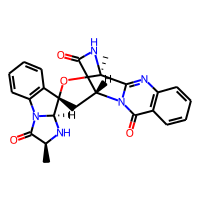
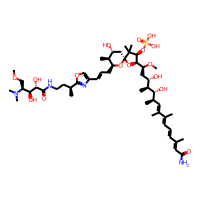
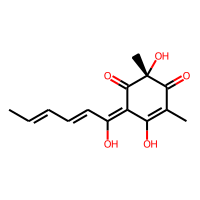
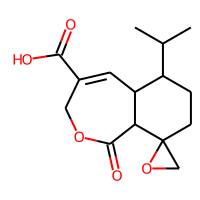
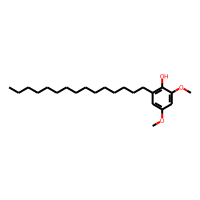
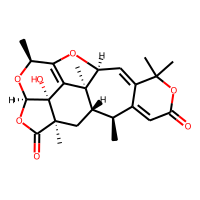
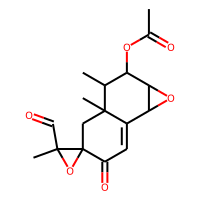
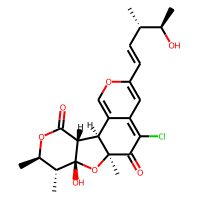
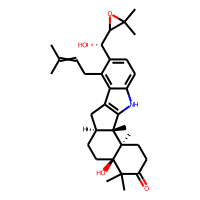
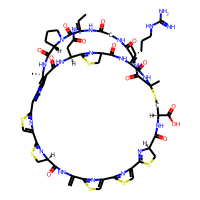

In [175]:
df_mibig[['ID','SMILES', 'Molecule']]

In [176]:
mibig_mols = list(df_mibig['Molecule'])

In [178]:
mibig_indexes = list(df_mibig['ID'])

In [179]:
start_time = time.time()
result_mibig_graphs = {}
disassembled_mibig_ids = {}
for mol_idx, current_mol in enumerate(mibig_mols):
    clear_output()
    print(f'PROGRESS: [{mol_idx+1}/{len(mibig_mols)}]')
    # Initialize Geass
    fragmentator = geass.Geass(current_mol, brokenBondsDefs, reactants, fillingAtoms, BULnames, verbose=0)

    # Get bonds to break
    fragmentator.get_bonds_to_break()
    
    # Create graph
    fragmentator.create_fragmentation_graph()
    
    # Get not NP fragments
    graph_nodes = list(fragmentator.graph.nodes(data=True))
    not_NP_fragments = {frag[0]: frag[1]['SMILES'] for frag in graph_nodes if frag[1]['isNP'] == 'No'}
    
    fragments = {}
    fragment_names = {}
    
    # Run metabolic disassembler
    for j, molecule_smiles in not_NP_fragments.items():
        # Iterate over the molecules

        disassembler = medi5.MetaDisassembler5() # Init the disassembler
        disassembler.output_folder = "./metadisassembler_v3_results" # Choose the output folder
        disassembler.useChirality = False # Whether to use Chilarity. IT HAS NOT BEEN TESTED IN 'TRUE' MODE
        disassembler.pbu = PBU # Assign the pbu
        disassembler.bul = BULv2 # Assign the bul
        disassembler.precomputed_qsu = False # We are not computed the qsu yet.
        disassembler.n_img = 1 
        disassembler.time_limit = 1
        name = str(j) + '_' + mibig_indexes[mol_idx]  # The name of the molecule
        molecule = Chem.MolFromSmiles(molecule_smiles) # The molecule from the current SMILES
        disassembler.input_molecule(molecule, name) # Define the input with the molecular structure and the name

        try:
            disassembler.disassemble() # disassemble
            #indexer[j] = disassembler.name
            #results[j] = disassembler.result
            #temp_qsu[j] = disassembler.query_specific_bul # IMPORTANT: SAVE THE QSU
            fragment_names[j] = [disassembler.query_specific_bul.names[disassembler.match_bu_idx[k]] for aux, k in enumerate(disassembler.result[0]["target"])]
            fragments[j] = [disassembler.query_specific_bul.cpds[disassembler.match_bu_idx[k]] for aux, k in enumerate(disassembler.result[0]["target"])]
        except:
            print('Error')
            #indexer[j] = 'Error'
            #results[j] = 'Error'
            #temp_qsu[j] = 'Error'
            fragments[j] = 'Error'
            fragment_names[j] = 'Error'


        #if len(disassembler.result) == 0:
            #fails.append(True)
        #else:
            #fails.append(False)
    # Add the Kegg ids to the id list of current compound
    disassembled_mibig_ids[mibig_indexes[mol_idx]] = []
    for names in fragment_names.values():
        if names != 'Error':
            disassembled_mibig_ids[mibig_indexes[mol_idx]] = disassembled_mibig_ids[mibig_indexes[mol_idx]] + names
    if 'Error' not in fragments.values():
        # Add new nodes and edges
        for not_NP_index in not_NP_fragments:
            # Creating new nodes list
            previous_graph_length = len(fragmentator.graph.nodes)
            new_nodes = [(i + previous_graph_length, {'SMILES': Chem.MolToSmiles(frag_mol.mol), 'img': geass.smi2image(Chem.MolToSmiles(frag_mol.mol)), 'isNP': 'Yes', 'kegg_id': fragment_names[not_NP_index][i][0]}) for i, frag_mol in enumerate(fragments[not_NP_index])]
            # Adding the nodes to the Geass graph
            fragmentator.graph.add_nodes_from(new_nodes)

            # Creating new edges list
            new_edges = []
            for fragment_index in range(len(fragments[not_NP_index])):
                new_edges.append((not_NP_index, fragment_index + previous_graph_length, {'reaction': 'unknown'}))
            # Adding the edges to the Geass graph
            fragmentator.graph.add_edges_from(new_edges)
    # Add the graph to the result graph list
    result_mibig_graphs[mibig_indexes[mol_idx]] = fragmentator
print(f"Elapsed: {round(time.time() - start_time, 3)}s")

PROGRESS: [14/8]
SMILES: CC
Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
Len seed_list before optimising: 1
Finished.
Elapsed: 1521.256s


In [196]:
compound_edges_mibig = {}
for shared_name, rg in result_mibig_graphs.items():
    current_edges = []
    #print(shared_name)
    for edge in list(rg.graph.edges(data=True)):
        current_kegg_id_0 = rg.graph.nodes[edge[0]]['kegg_id']
        current_kegg_id_1 = rg.graph.nodes[edge[1]]['kegg_id']
        if current_kegg_id_0 == 'NA':
            edge0name = rg.get_all_NA_neighbours_names(edge[0])
        else:
            edge0name = current_kegg_id_0[0] if type(current_kegg_id_0) == tuple else current_kegg_id_0
        if current_kegg_id_1 == 'NA':
            edge1name = rg.get_all_NA_neighbours_names(edge[1])
        else:
            edge1name = current_kegg_id_1[0] if type(current_kegg_id_1) == tuple else current_kegg_id_1
        current_edges.append((edge0name, edge1name, edge[2]['reaction']))
    compound_edges_mibig[shared_name] = tuple(current_edges)

In [197]:
compound_edges_mibig

{'10003515': (('C00077+C00001+C01407+C14403+C00001+C00014+C01845',
   'C00163',
   'amideR'),
  ('C00077+C00001+C01407+C14403+C00001+C00014+C01845', 'C00014', 'aminesR'),
  ('C00077+C00001+C01407+C14403+C00001+C00014+C01845', 'C00077', 'unknown'),
  ('C00077+C00001+C01407+C14403+C00001+C00014+C01845', 'C00001', 'unknown'),
  ('C00077+C00001+C01407+C14403+C00001+C00014+C01845', 'C01407', 'unknown'),
  ('C00077+C00001+C01407+C14403+C00001+C00014+C01845', 'C14403', 'unknown'),
  ('C00077+C00001+C01407+C14403+C00001+C00014+C01845', 'C00001', 'unknown'),
  ('C00077+C00001+C01407+C14403+C00001+C00014+C01845', 'C00014', 'unknown'),
  ('C00077+C00001+C01407+C14403+C00001+C00014+C01845', 'C01845', 'unknown'),
  ('C00163', 'C00014', 'aminesR')),
 '10011292': (('C01801+C06701+C01438+C01438+C11271+C00001+C01438+C01438+C20335+C20783',
   'C00132',
   'etherR'),
  ('C01801+C06701+C01438+C01438+C11271+C00001+C01438+C01438+C20335+C20783',
   'C02640+C00797+C00001+C01438',
   'olefin'),
  ('C01801+C067

In [200]:
compound_edges_all = compound_edges.copy()

In [201]:
compound_edges_all.update(compound_edges_mibig)

In [202]:
print(len(compound_edges))
print(len(compound_edges_mibig))
print(len(compound_edges_all))

1853
2307
4160


In [205]:
start = time.time()
similarity_matrix_all = []
for i, sent_i in enumerate(compound_edges_all.values()):
    templist = []
    for j, sent_j in enumerate(compound_edges_all.values()):
        #templist.append(geass.jaccard_similarity(sent_i, sent_j))
        if i == j:
            templist.append(1)
        else:
            templist.append(jaccard_similarity(sent_i, sent_j))
    similarity_matrix_all.append(templist)
similarity_df_all = pd.DataFrame(similarity_matrix_all, index=list(compound_edges_all.keys()), columns=list(compound_edges_all.keys()))
print(f"Elapsed: {round(time.time() - start, 3)}s")

Elapsed: 241.475s


In [206]:
similarity_df_all

,SF_0293,SF_0298,SF_0446,SF_0197,BS_0894,BS_1574,SF_0068,SF_0401,BS_1033,BS_0042,...,Friulimicin C,lymphostin,radamycin,Pyrrolomycin C,Thuggacin A,Paraherquonin,PR-toxin,11-epichaetomugilin A,sespendole,cyclothiazomycin b1
SF_0293,1,0,0,0.0,0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
SF_0298,0,1,0,0.0,0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
SF_0446,0,0,1,0.0,0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
SF_0197,0,0,0,1.0,0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BS_0894,0,0,0,0.0,1,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Paraherquonin,0,0,0,0.0,0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
PR-toxin,0,0,0,0.0,0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
11-epichaetomugilin A,0,0,0,0.0,0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
sespendole,0,0,0,0.0,0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [207]:
#similarity_df_all.to_csv('similarity_matrix_mibig.csv')

In [263]:
reactants

{'urea': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4870>,
 'ureaR': <rdkit.Chem.rdchem.Mol at 0x7f557d5b48d0>,
 'amide': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4930>,
 'amideR': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4bd0>,
 'ester': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4c30>,
 'amines': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4c90>,
 'aminesR': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4cf0>,
 'cyclicAmines': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4d50>,
 'ether': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4db0>,
 'etherR': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4e10>,
 'olefin': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4e70>,
 'arNalC': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4ed0>,
 'laNalC': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4f30>,
 'arCarC': <rdkit.Chem.rdchem.Mol at 0x7f557d5b4f90>,
 'arCarCR': <rdkit.Chem.rdchem.Mol at 0x7f557d321030>,
 'arNarC': <rdkit.Chem.rdchem.Mol at 0x7f557d321090>,
 'arNarCR': <rdkit.Chem.rdchem.Mol at 0x7f557d3210f0>,
 'sulphonamide': <rdkit.Chem.rdchem.Mol at 0x7f557d321150>}

In [264]:
with open('backups/' + 'result_graphs.pkl', 'wb') as f:
    pickle.dump(result_graphs, f)

RuntimeError: Pickling of "rdkit.Chem.rdchem.QueryBond" instances is not enabled (http://www.boost.org/libs/python/doc/v2/pickle.html)

In [268]:
[n for n in result_graphs['BS_0008'].graph.nodes(data=True)]

[(0,
  {'SMILES': '[H]OC1OC(CO)C(O)C(O)C1O',
   'img': 'data:image/svg+xml;charset=utf-8,%3C%3Fxml%20version%3D%271.0%27%20encoding%3D%27iso-8859-1%27%3F%3E%0A%3Csvg%20version%3D%271.1%27%20baseProfile%3D%27full%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3D%27http%3A%2F%2Fwww.w3.org%2F2000%2Fsvg%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Ardkit%3D%27http%3A%2F%2Fwww.rdkit.org%2Fxml%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Axlink%3D%27http%3A%2F%2Fwww.w3.org%2F1999%2Fxlink%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xml%3Aspace%3D%27preserve%27%0Awidth%3D%27350px%27%20height%3D%27300px%27%20viewBox%3D%270%200%20350%20300%27%3E%0A%3C%21--%20END%20OF%20HEADER%20--%3E%0A%3Crect%20style%3D%27opacity%3A1.0%3Bfill%3A%23FFFFFF%3Bstroke%3Anone%27%20width%3D%27350.0%27%20height%3D%27300.0%27%20x%3D%270.0%27%20y%3D%270.0%27%3E%20%3C%2Frect%3E%0A%3Cpath%20class%3D%27bond-0%20atom-0%20atom-1%27%20d%3D%2